In [632]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import math
import scipy.stats as stats
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
import datetime
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

#Load data
teams = pd.read_csv('data/clean_teams.csv')

teams

,Unnamed: 0,year,tmID,confID,playoff,firstRound,semis,finals,o_fgm,o_fga,...,won,lost,GP,homeW,homeL,awayW,awayL,confW,confL,min
0,0,9,ATL,EA,N,NaN,NaN,NaN,895,2258,...,4,30,34,1,16,3,14,2,18,6825
1,1,10,ATL,EA,Y,L,NaN,NaN,1089,2428,...,18,16,34,12,5,6,11,10,12,6950
2,2,1,CHA,EA,N,NaN,NaN,NaN,812,1903,...,8,24,32,5,11,3,13,5,16,6475
3,3,2,CHA,EA,Y,W,W,L,746,1780,...,18,14,32,11,5,7,9,15,6,6500
4,4,3,CHA,EA,Y,L,NaN,NaN,770,1790,...,18,14,32,11,5,7,9,12,9,6450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,EA,N,NaN,NaN,NaN,847,1968,...,16,18,34,10,7,6,11,9,11,6900
138,138,7,WAS,EA,Y,L,NaN,NaN,1016,2199,...,18,16,34,13,4,5,12,12,8,6850
139,139,8,WAS,EA,N,NaN,NaN,NaN,877,2170,...,16,18,34,8,9,8,9,8,12,6900
140,140,9,WAS,EA,N,NaN,NaN,NaN,885,2131,...,10,24,34,6,11,4,13,6,14,6825


In [633]:
teams['playoff'] = (teams['playoff'] == 'Y').astype(int)
#teams = pd.get_dummies(teams, columns=['tmID'])
teams['firstRound'] = teams['firstRound'].fillna(0)
teams['firstRound'] = teams['firstRound'].replace('W',1)
teams['firstRound'] = teams['firstRound'].replace('L',1)

teams['semis'] = teams['semis'].fillna(0)
teams['semis'] = teams['semis'].replace('W',1)
teams['semis'] = teams['semis'].replace('L',1)

teams['finals'] = teams['finals'].fillna(0)
teams['finals'] = teams['finals'].replace('W',2)
teams['finals'] = teams['finals'].replace('L',1)

teams['playoff_result'] = teams['firstRound'] + teams['semis'] + teams['finals']

teams = teams.drop(['firstRound','semis','finals'], axis=1)

teams['east'] = (teams['confID'] == 'EA').astype(int)
teams['west'] = (teams['confID'] == 'WE').astype(int)

teams.drop('confID', axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeW,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west
0,0,9,ATL,0,895,2258,542,725,202,598,...,1,16,3,14,2,18,6825,0,1,0
1,1,10,ATL,1,1089,2428,569,755,114,374,...,12,5,6,11,10,12,6950,1,1,0
2,2,1,CHA,0,812,1903,431,577,131,386,...,5,11,3,13,5,16,6475,0,1,0
3,3,2,CHA,1,746,1780,410,528,153,428,...,11,5,7,9,15,6,6500,3,1,0
4,4,3,CHA,1,770,1790,490,663,211,527,...,11,5,7,9,12,9,6450,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,10,7,6,11,9,11,6900,0,1,0
138,138,7,WAS,1,1016,2199,528,715,187,522,...,13,4,5,12,12,8,6850,1,1,0
139,139,8,WAS,0,877,2170,668,839,163,528,...,8,9,8,9,8,12,6900,0,1,0
140,140,9,WAS,0,885,2131,435,659,163,460,...,6,11,4,13,6,14,6825,0,1,0


In [634]:
teams['win_ratio'] = teams['won'] / teams['GP']
teams['win_ratio'] = teams['win_ratio'].apply(lambda x: round(x, 2))

teams.drop(['won','lost', 'GP'], axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio
0,0,9,ATL,0,895,2258,542,725,202,598,...,16,3,14,2,18,6825,0,1,0,0.12
1,1,10,ATL,1,1089,2428,569,755,114,374,...,5,6,11,10,12,6950,1,1,0,0.53
2,2,1,CHA,0,812,1903,431,577,131,386,...,11,3,13,5,16,6475,0,1,0,0.25
3,3,2,CHA,1,746,1780,410,528,153,428,...,5,7,9,15,6,6500,3,1,0,0.56
4,4,3,CHA,1,770,1790,490,663,211,527,...,5,7,9,12,9,6450,1,1,0,0.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,7,6,11,9,11,6900,0,1,0,0.47
138,138,7,WAS,1,1016,2199,528,715,187,522,...,4,5,12,12,8,6850,1,1,0,0.53
139,139,8,WAS,0,877,2170,668,839,163,528,...,9,8,9,8,12,6900,0,1,0,0.47
140,140,9,WAS,0,885,2131,435,659,163,460,...,11,4,13,6,14,6825,0,1,0,0.29


In [635]:
#Possessions = Team Possessions = 0.5 * ((Team FGA + 0.4 * Team FTA - 1.07 * (Team OREB / (Team OREB + Opponent DREB)) * (Team FGA - Team FG) + Team TO) + (Opponent FGA + 0.4 * Opponent FTA - 1.07 * (Opponent OREB / (Opponent OREB + Team DREB)) * (Opponent FGA - Opponent FG) + Opponent TO))
teams['possesions'] = 0.5 * (teams['o_fga'] + 0.4 * teams['o_fta'] - 1.07 * (teams['o_oreb'] / (teams['o_oreb'] + teams['d_dreb'])) * (teams['o_fga'] - teams['o_fgm']) + teams['o_to']+
                             teams['d_fga'] + 0.4 * teams['d_fta'] - 1.07 * (teams['d_oreb'] / (teams['d_oreb'] + teams['o_dreb'])) * (teams['d_fga'] - teams['d_fgm']) + teams['d_to'])

In [636]:
#OFF EFF = 100 x (Points / Possessions)
teams['off_rtg'] = 100 * (teams['o_pts'] / teams['possesions'])
teams['off_rtg'] = teams['off_rtg'].apply(lambda x: round(x, 1))

#DEF EFF = 100 x (Opponent Points / Opponent Possessions)
teams['def_rtg'] = 100 * (teams['d_pts'] / teams['possesions'])
teams['def_rtg'] = teams['def_rtg'].apply(lambda x: round(x, 1))

# NET EFF = OFF EFF - DEF EFF
teams['net_rtg'] = teams['off_rtg'] - teams['def_rtg']
teams['net_rtg'] = teams['net_rtg'].apply(lambda x: round(x, 1))

teams.drop(['possesions', 'off_rtg', 'def_rtg'], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,895,2258,542,725,202,598,...,3,14,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,1089,2428,569,755,114,374,...,6,11,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,812,1903,431,577,131,386,...,3,13,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,746,1780,410,528,153,428,...,7,9,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,770,1790,490,663,211,527,...,7,9,12,9,6450,1,1,0,0.56,5.1


In [637]:
teams.drop(["o_fgm", "o_fga", "o_ftm", "o_fta", "o_3pm", "o_3pa", "o_oreb", "o_dreb", "o_reb", "o_asts", "o_pf", "o_stl", "o_to", "o_blk", "o_pts"], axis=1, inplace=True)
teams.drop(["d_fgm", "d_fga", "d_ftm", "d_fta", "d_3pm", "d_3pa", "d_oreb", "d_dreb", "d_reb", "d_asts", "d_pf", "d_stl", "d_to", "d_blk", "d_pts", "homeW", "homeL", "awayW", "awayL"], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1


In [638]:
players_teams_data = pd.read_csv("data/players_teams.csv")

In [639]:
# delete players who haven't played
players_teams_data = players_teams_data[players_teams_data['minutes'] != 0]

#players_teams_data['UE'] = (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'] + players_teams_data['turnovers']) * 100 / players_teams_data['minutes']
players_teams_data['PPG'] = players_teams_data['points'] / players_teams_data['GP']
players_teams_data['SPG'] = players_teams_data['steals'] / players_teams_data['GP']
players_teams_data['TOVPG'] = players_teams_data['turnovers'] / players_teams_data['GP']



#players_teams_data['x'] = players_teams_data['points'] / (players_teams_data['fgAttempted'] + players_teams_data['fgAttempted'] + players_teams_data['turnovers'] - players_teams_data['oRebounds'])
#players_teams_data['x'] = players_teams_data['points'] / 2* (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'])
#players_teams_data['x'] = players_teams_data['rebounds'] / players_teams_data['GP']
#players_teams_data['x'] = players_teams_data['fgMade'] / players_teams_data['fgAttempted']
#players_teams_data['x'] = players_teams_data['assists'] / players_teams_data['GP']
#players_teams_data['x'] = players_teams_data['blocks'] / players_teams_data['GP']

#players_teams_data['PPP'] = players_teams_data['points'] / (players_teams_data['fgAttempted'] + players_teams_data['fgAttempted'] + players_teams_data['turnovers'] - players_teams_data['oRebounds'])
#players_teams_data['TSP'] = players_teams_data['points'] / 2* (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'])
# players_teams_data['RPG'] = players_teams_data['rebounds'] / players_teams_data['GP']
#players_teams_data['FER'] = players_teams_data['fgMade'] / players_teams_data['fgAttempted']
#players_teams_data['APG'] = players_teams_data['assists'] / players_teams_data['GP']
#players_teams_data['BPG'] = players_teams_data['blocks'] / players_teams_data['GP']

In [640]:
players_teams_data['PPG'] = players_teams_data['PPG'].apply(lambda x: round(x, 1))

players_teams_data['SPG'] = players_teams_data['SPG'].apply(lambda x: round(x, 1))

players_teams_data['TOVPG'] = players_teams_data['TOVPG'].apply(lambda x: round(x, 1))

players_teams_data[['playerID', 'year', 'PPG', 'SPG', 'TOVPG']]

,playerID,year,PPG,SPG,TOVPG
0,abrossv01w,2,13.2,1.6,3.3
1,abrossv01w,3,11.6,1.6,3.4
2,abrossv01w,4,10.6,1.5,3.0
3,abrossv01w,5,6.6,1.4,2.0
4,abrossv01w,6,9.8,1.5,2.6
...,...,...,...,...,...
1871,zakalok01w,3,1.2,0.0,0.8
1872,zarafr01w,6,2.6,0.5,1.2
1873,zellosh01w,10,11.9,0.8,2.3
1874,zirkozu01w,4,1.8,0.0,0.3


In [641]:
players_teams_data.drop(["points", "steals", 'turnovers', "GP"], axis=1, inplace=True)
players_teams_data

,playerID,year,stint,tmID,lgID,GS,minutes,oRebounds,dRebounds,rebounds,...,PostfgAttempted,PostfgMade,PostftAttempted,PostftMade,PostthreeAttempted,PostthreeMade,PostDQ,PPG,SPG,TOVPG
0,abrossv01w,2,0,MIN,WNBA,23,846,43,131,174,...,0,0,0,0,0,0,0,13.2,1.6,3.3
1,abrossv01w,3,0,MIN,WNBA,27,805,45,101,146,...,0,0,0,0,0,0,0,11.6,1.6,3.4
2,abrossv01w,4,0,MIN,WNBA,25,792,44,97,141,...,22,6,8,8,7,3,0,10.6,1.5,3.0
3,abrossv01w,5,0,MIN,WNBA,11,462,17,57,74,...,23,8,4,2,8,2,0,6.6,1.4,2.0
4,abrossv01w,6,0,MIN,WNBA,31,777,29,78,107,...,0,0,0,0,0,0,0,9.8,1.5,2.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1871,zakalok01w,3,2,PHO,WNBA,0,37,0,3,3,...,0,0,0,0,0,0,0,1.2,0.0,0.8
1872,zarafr01w,6,0,SEA,WNBA,4,413,11,28,39,...,6,4,2,2,1,1,0,2.6,0.5,1.2
1873,zellosh01w,10,0,DET,WNBA,4,802,25,81,106,...,68,24,27,23,17,7,0,11.9,0.8,2.3
1874,zirkozu01w,4,0,WAS,WNBA,0,30,0,2,2,...,0,0,0,0,0,0,0,1.8,0.0,0.3


In [642]:
average_ppg = players_teams_data.groupby(['year', 'tmID'])['PPG'].mean().reset_index()
average_ppg['PPG'] = average_ppg['PPG'].apply(lambda x: round(x, 2))
average_ppg

average_spg = players_teams_data.groupby(['year', 'tmID'])['SPG'].mean().reset_index()
average_spg['SPG'] = average_spg['SPG'].apply(lambda x: round(x, 2))
average_spg

average_tovpg= players_teams_data.groupby(['year', 'tmID'])['TOVPG'].mean().reset_index()
average_tovpg['TOVPG'] = average_tovpg['TOVPG'].apply(lambda x: round(x, 2))
average_tovpg

,year,tmID,TOVPG
0,1,CHA,1.42
1,1,CLE,1.53
2,1,DET,1.40
3,1,HOU,1.22
4,1,IND,1.30
...,...,...,...
137,10,PHO,1.43
138,10,SAC,1.38
139,10,SAS,1.58
140,10,SEA,1.49


In [643]:
teams = pd.merge(teams, average_ppg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_ppg'))
teams = pd.merge(teams, average_spg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_ppg'))
teams = pd.merge(teams, average_tovpg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_tovpg'))
teams

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg,PPG,SPG,TOVPG
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7,6.45,0.84,1.41
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3,7.34,0.88,1.52
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7,6.45,0.65,1.42
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2,5.75,0.59,1.42
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1,5.69,0.67,0.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,9,11,6900,0,1,0,0.47,-1.9,5.62,0.72,1.10
138,138,7,WAS,1,12,8,6850,1,1,0,0.53,3.4,7.67,0.87,1.44
139,139,8,WAS,0,8,12,6900,0,1,0,0.47,-2.1,6.31,0.79,1.27
140,140,9,WAS,0,6,14,6825,0,1,0,0.29,-9.0,5.53,0.56,1.52


In [644]:
teams_previous_year = teams.copy()

# 'year_previous' - ano atual menos 1
teams_previous_year['year_previous'] = teams_previous_year['year'] - 1

# Selecionar algumas colunas (ajuste conforme necessário para sua análise)
columns_to_include = ['playoff_result', 'win_ratio', 'net_rtg', 'PPG', 'SPG', 'TOVPG']
teams_previous_year = teams_previous_year[['year_previous', 'tmID'] + columns_to_include]

teams_previous_year.columns = ['year_previous', 'tmID'] + [f'{col}_previous' for col in columns_to_include]

teams = pd.merge(teams, teams_previous_year, how='left', left_on=['year', 'tmID'], right_on=['year_previous', 'tmID'])

teams = teams.drop(['year_previous'], axis=1)

print(teams['year'].unique())


[ 9 10  1  2  3  4  5  6  7  8]


[ 9 10  1  2  3  4  5  6  7  8]


<AxesSubplot:>

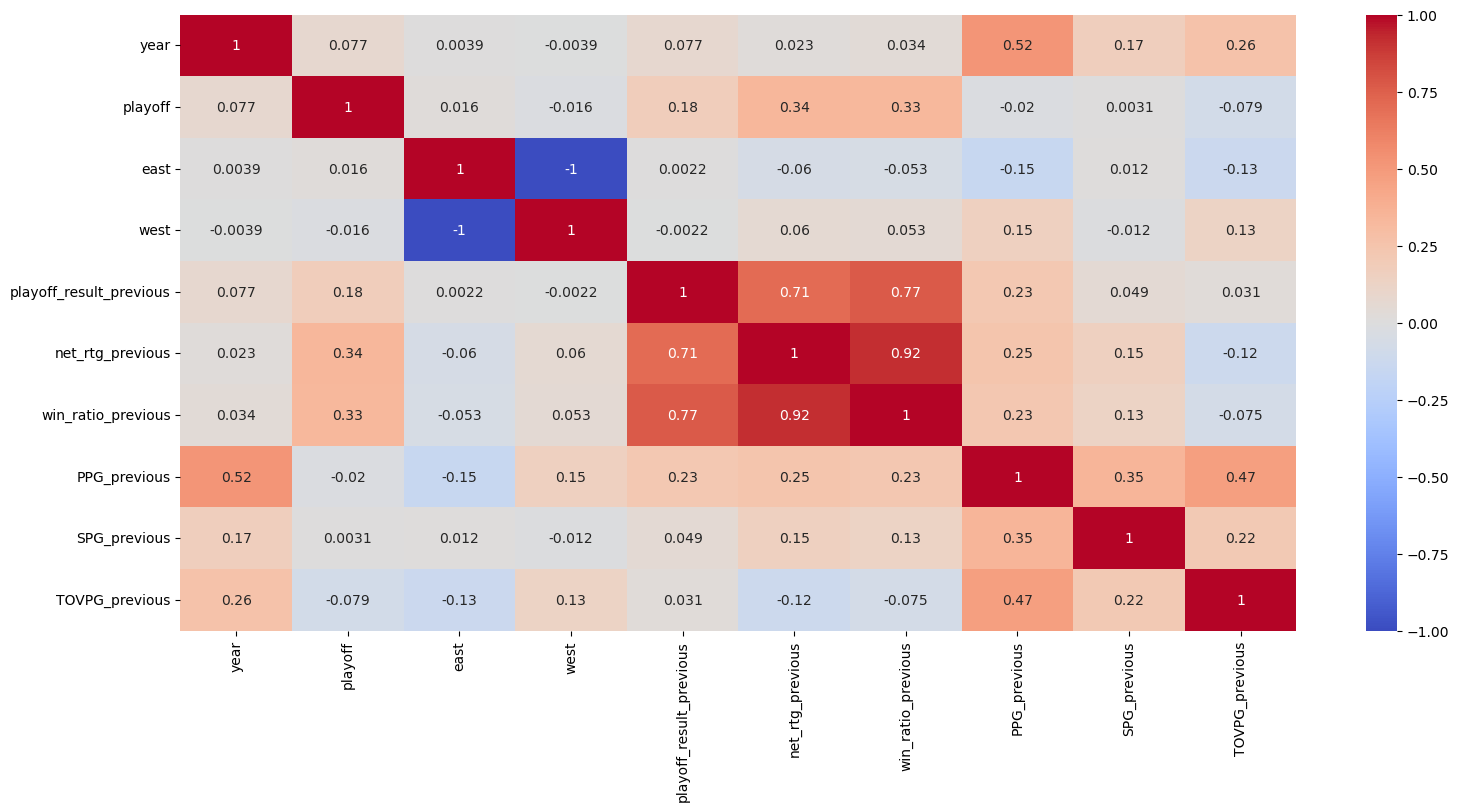

In [645]:
teams = teams[['year', 'tmID','playoff','east','west','playoff_result_previous','net_rtg_previous','win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']]
print(teams['year'].unique())
plt.figure(figsize=(18,8))
correlation = teams.corr()
sb.heatmap(correlation,annot=True,cmap='coolwarm')

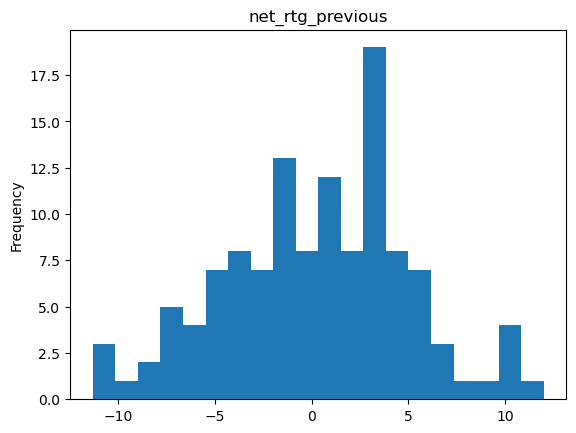

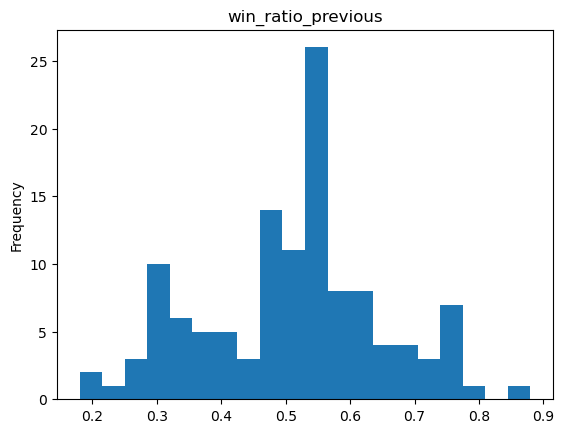

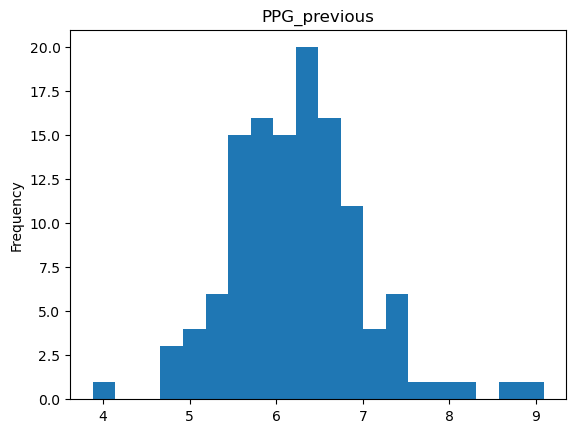

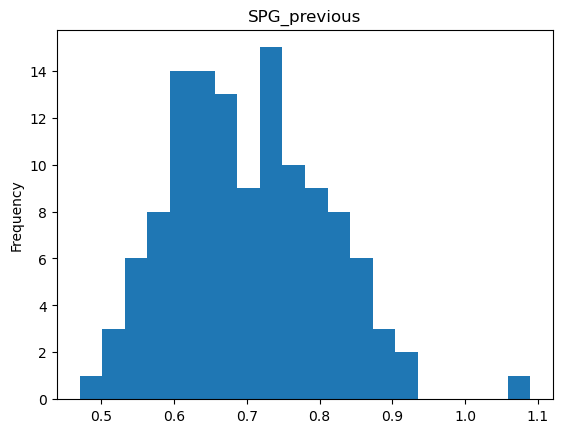

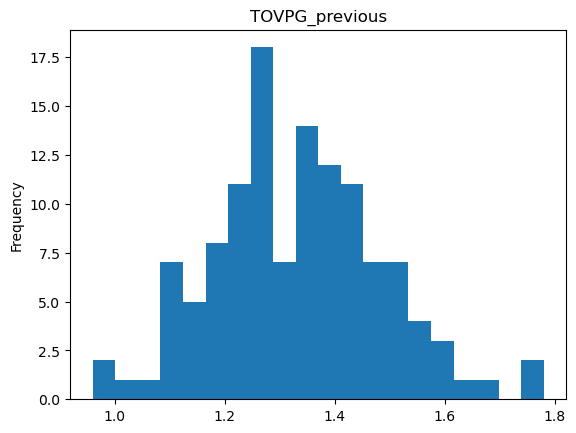

In [646]:
columns = ['net_rtg_previous', 'win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']

for col in columns:
    teams[col].plot(kind='hist', bins=20, title=col)
    plt.show()

In [647]:
for col in columns:
    skewness = teams[col].skew()
    print(f"Assimetria de {col}: {skewness}")

Assimetria de net_rtg_previous: -0.12353953591475184
Assimetria de win_ratio_previous: -0.02830937966344089
Assimetria de PPG_previous: 0.4900557361498436
Assimetria de SPG_previous: 0.5114511258256632
Assimetria de TOVPG_previous: 0.2615186751426452


Assimetria:
    kosjcdnndc

In [648]:
#teams.dropna(inplace=True) 

for col in ['net_rtg_previous', 'win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']:
    if(col == 'net_rtg_previous' and 'win_ratio_previous'):
        teams[col].fillna(teams[col].mean(), inplace=True)
    else:
        teams[col].fillna(teams[col].median(), inplace=True)

teams = teams.dropna(subset=['playoff_result_previous'])



In [649]:
new_df = teams[['year','playoff','east','west', 'playoff_result_previous','net_rtg_previous','win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']]

print(new_df['year'].unique())

[9 1 2 3 4 5 6 7 8]


## Testing models using Sliding Window

In [650]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC   
from sklearn.decomposition import PCA

column_names = new_df.drop(['year', 'playoff'], axis=1).columns.tolist()
def sliding_window_split(new_df, window_size, target_column,n_components=0):
    splits = []
    test_years = []
    min_year = new_df['year'].min()
    max_year = new_df['year'].max() 
    print("Min Year:", min_year)
    print("Max Year:", max_year)

    for start_year in range(min_year, max_year - window_size + 1):
        end_year = start_year + window_size - 1
        test_year = end_year + 1
        test_years.append(test_year)
       
        train_mask = (new_df['year'] >= start_year) & (new_df['year'] <= end_year)
        X_train = new_df[train_mask].drop([target_column], axis=1)
        y_train = new_df[train_mask][target_column]
        print("Training Years:", start_year ," to ", end_year)  

        # Dados de teste
        test_mask = new_df['year'] == end_year + 1
        X_test = new_df[test_mask].drop([target_column], axis=1)
        y_test = new_df[test_mask][target_column]
        print("Testing Year:", end_year +1)  # Imprime o ano de teste
        print("")

        # Remover a coluna 'year'
        X_train = X_train.drop(['year'], axis=1)
        X_test = X_test.drop(['year'], axis=1)

        if n_components > 0:
            pca = PCA(n_components=n_components)
            pca.fit(X_train)
            X_train = pca.transform(X_train)
            X_test = pca.transform(X_test)

        splits.append((X_train, X_test, y_train, y_test))

    return splits,test_years

window_size = 4 
target_column = 'playoff'
teams = pd.get_dummies(teams, columns=['tmID']) 
splits,test_years = sliding_window_split(teams, window_size, target_column)


Min Year: 1
Max Year: 9
Training Years: 1  to  4
Testing Year: 5

Training Years: 2  to  5
Testing Year: 6

Training Years: 3  to  6
Testing Year: 7

Training Years: 4  to  7
Testing Year: 8

Training Years: 5  to  8
Testing Year: 9



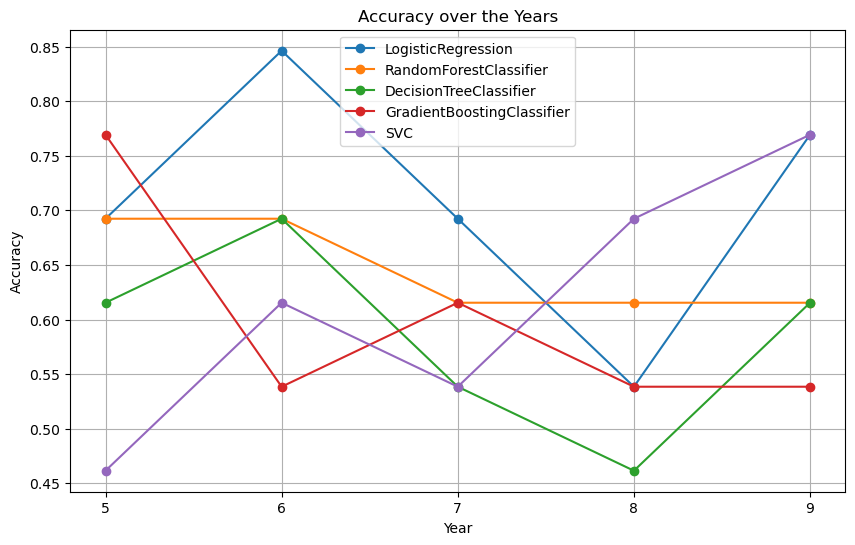

In [651]:
import matplotlib.pyplot as plt

models = [
    LogisticRegression(random_state=42),
    RandomForestClassifier(n_estimators=200, random_state=42),
    DecisionTreeClassifier(random_state=42),
    GradientBoostingClassifier(n_estimators=100, random_state=42),SVC(random_state=42)
    
]

accuracies = {model.__class__.__name__: [] for model in models}
roc_auc_scores = {model.__class__.__name__: [] for model in models}

for split,test_year in zip(splits, test_years): 
    X_train, X_test, y_train, y_test = split

    for model in models:
        model_name = model.__class__.__name__

        model.fit(X_train, y_train)
        accuracy = model.score(X_test, y_test)
        #predictions = model.predict(X_test)

        #print(f"Model: {model_name}, Accuracy: {accuracy}")
        accuracies[model_name].append(accuracy)

        # Calculate probability estimates for ROC AUC score
        if hasattr(model, "predict_proba"):
            y_scores = model.predict_proba(X_test)[:, 1]
        else:  # Use decision function for models that don't have predict_proba
            y_scores = model.decision_function(X_test)
        
        # ROC AUC score
        roc_auc = roc_auc_score(y_test, y_scores)
        roc_auc_scores[model_name].append(roc_auc)


plt.figure(figsize=(10, 6))  # Defina o tamanho do gráfico

for model_name, accuracy_list in accuracies.items():
    plt.plot(test_years, accuracy_list, marker='o', label=model_name)

plt.title('Accuracy over the Years')
plt.xlabel('Year')
plt.ylabel('Accuracy')
plt.xticks(test_years)  
plt.legend()  
plt.grid(True)  
plt.show()




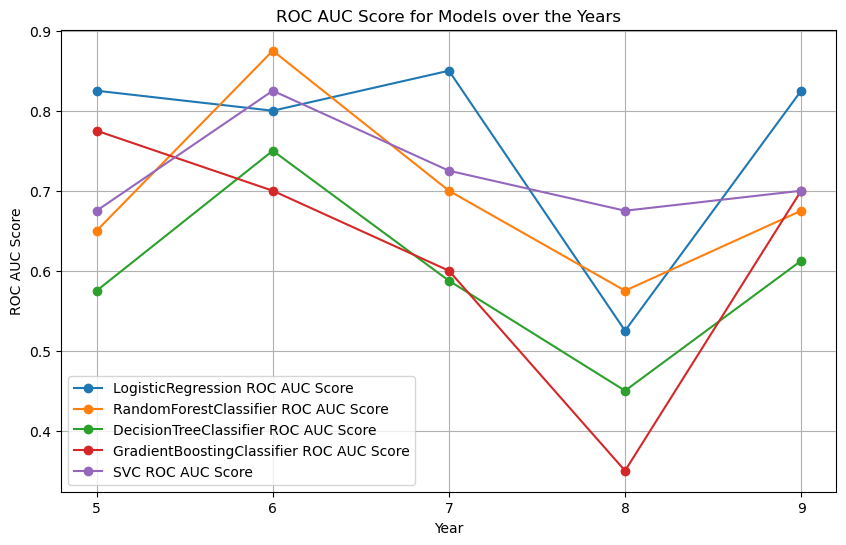

In [652]:
plt.figure(figsize=(10, 6))

# Plot the ROC AUC scores for all models
for model_name, roc_auc_list in roc_auc_scores.items():
    plt.plot(test_years, roc_auc_list, marker='o', label=f'{model_name} ROC AUC Score')

plt.title('ROC AUC Score for Models over the Years')
plt.xlabel('Year')
plt.ylabel('ROC AUC Score')
plt.xticks(test_years)
plt.legend()
plt.grid(True)
plt.show()

## Feature Aggregation : Principal Component Analysis

Min Year: 1
Max Year: 9
Training Years: 1  to  4
Testing Year: 5

Training Years: 2  to  5
Testing Year: 6

Training Years: 3  to  6
Testing Year: 7

Training Years: 4  to  7
Testing Year: 8

Training Years: 5  to  8
Testing Year: 9



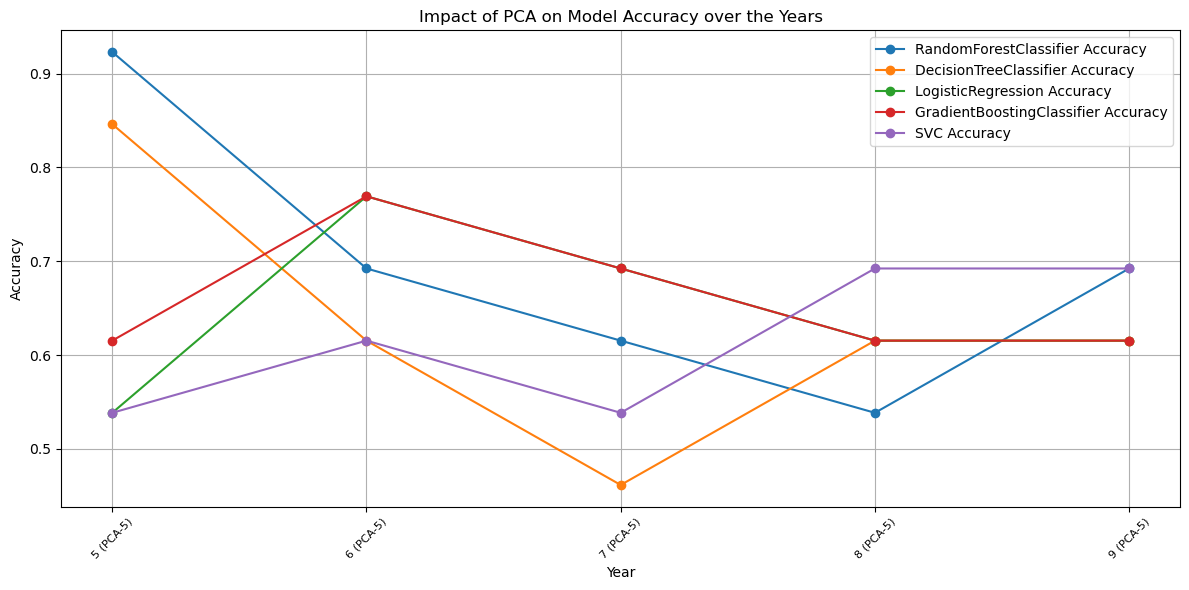

In [653]:

window_size = 4 
target_column = 'playoff'
#teams = pd.get_dummies(teams, columns=['tmID']) 

n_components = 5  
models = [RandomForestClassifier(n_estimators=200, random_state=42), 
          DecisionTreeClassifier(random_state=42), 
          LogisticRegression(random_state=42),
          GradientBoostingClassifier(n_estimators=100, random_state=42),
          SVC(random_state=42)]
accuracies = {model.__class__.__name__: [] for model in models}

splits,test_years = sliding_window_split(teams, window_size, target_column, n_components)
    
for X_train, X_test, y_train, y_test in splits:
    
    for model in models:
        model_name = model.__class__.__name__
        model.fit(X_train, y_train)
        accuracy = model.score(X_test, y_test)
        accuracies[model_name].append(accuracy)


plt.figure(figsize=(12, 6))

for model_name, accuracy_list in accuracies.items():
    formatted_years = [f"{year} (PCA-{n_components})" for year in test_years]
    plt.plot(formatted_years, accuracy_list, marker='o', label=f'{model_name} Accuracy')

plt.title('Impact of PCA on Model Accuracy over the Years')
plt.xlabel('Year')
plt.ylabel('Accuracy')
plt.xticks(rotation=45, fontsize=8)  
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


## Hyperparameter Tuning with GridSearch

